In [ ]:
!pip install optuna plotly lightgbm scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 15.2 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import optuna
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, r2_score
from lightgbm import LGBMClassifier

# Загрузим данные

- Данные упорядочены по времени
- Задача - предсказать `target`
- Фичи - `feature_i`
- Трейн, валидация и тест уже определены (см. колонку `sample_part`)

In [ ]:
df = pd.read_parquet('df.parquet.gzip')
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 500000 entries, 22620 to 310653
Columns: 235 entries, date to sample_part
dtypes: category(2), datetime64[ms](1), datetime64[ns](2), float64(220), int64(9), object(1)
memory usage: 893.6+ MB


In [ ]:
df.head()

,date,month,quarter,feature_217,feature_66,feature_9,feature_193,feature_15,feature_199,feature_25,...,feature_20,feature_188,feature_71,feature_106,feature_14,feature_92,feature_179,feature_102,target,sample_part
22620,2021-01-01,2021-01-01,2021-01-01,1.180855,0.483118,13.976791,1.135021,43.271792,-46.888875,97.558366,...,23.745198,-32.001093,85.489903,1.454045,-195.725786,3.719083,1,-28.813537,0.0,train
478621,2021-01-01,2021-01-01,2021-01-01,3.427814,0.886778,27.158209,-0.378728,80.087863,-67.242703,105.803406,...,22.902111,-37.436243,71.735619,1.657242,-176.250404,3.277817,1,-45.987721,1.0,train
372254,2021-01-01,2021-01-01,2021-01-01,-38.555018,1.227175,19.893873,0.498787,98.464365,-67.402522,81.858076,...,21.848414,-51.872841,65.363236,1.626874,-178.116798,2.028950,0,-31.074122,1.0,train
2596,2021-01-01,2021-01-01,2021-01-01,-14.666558,0.753129,18.203010,-1.200014,117.331340,-25.557745,90.277266,...,26.134586,-49.703003,65.013659,1.170023,-192.232264,2.218177,1,-36.703897,0.0,train
216892,2021-01-01,2021-01-01,2021-01-01,6.734990,1.129100,11.245920,-0.108955,61.205722,-78.397406,82.637472,...,24.201039,-41.070219,69.986127,1.630795,-200.155528,3.055104,1,-44.672299,1.0,train


In [ ]:
TARGET = 'target'
N_FEATURES = 230
features = [f'feature_{i}' for i in range(N_FEATURES)]

# Первичный отбор признаков... (1 балл)

**Задание:** Сначала отсеем совсем уж мусорные признаки.

Воспользовавшись вашим кодом для вычисления `IV` из прошлой домашки, для всех **числовых** фичей вычислите `IV` на 20 бакетах. Отсейте признаки с `IV < 0.005`.

**Hint:** паркет не всегда сохраняет `dtype` колонки. Чтобы проверить признаки на "реальный" тип данных, лучше на всякий случай посмотреть на `nunique`

In [ ]:
from scipy.special import logit
from typing import Union, Tuple


def woe_transform(badrate : float, offset : float) -> float:
    """Считаем WoE для бакета с данным badrate и выборки
    с данным offset."""
    woe = logit(badrate) - offset
    return woe

def calc_buckets(x : Union[np.ndarray, pd.Series], n_buckets : int) -> np.ndarray:
    """Разбивает массив значений признака x на
    n_buckets бакетов"""

    x = pd.Series(x).reset_index(drop=True)
    buckets = x.rank(method="dense", pct=True) * n_buckets
    buckets = np.ceil(buckets) - 1   # np.floor дает другой результат для 5.0, 6.0 и т.д.
    buckets = buckets.fillna(-1)

    return np.array(buckets, dtype=np.int16)


def calc_plot_title(
        values : np.ndarray,
        target : np.ndarray,
        buckets : np.ndarray
    ) -> str:
    # формула выше
    df = pd.DataFrame({'value': values, 'target': target, 'bucket': buckets})

    df_buckets = df.groupby('bucket').agg(
        bads=('target', 'sum'),
        goods=('target', lambda x: (x == 0).sum()),
    ).sort_index()

    B_total = df_buckets['bads'].sum()
    G_total = df_buckets['goods'].sum()

    if B_total == 0 or G_total == 0:
        return 0.0

    offset = logit(B_total / (B_total + G_total))

    total_per_bucket = df_buckets['bads'] + df_buckets['goods']
    woe = woe_transform(df_buckets['bads'] / total_per_bucket, offset)

    bad_dist = df_buckets['bads'] / B_total
    good_dist = df_buckets['goods'] / G_total

    IV = np.sum((bad_dist - good_dist) * woe)

    return IV

In [ ]:
X_train = df[df['sample_part'] == 'train'].reset_index(drop=True)
y_train = X_train['target'].values

num_features = []
cat_features = []

for col in features:
  n = X_train[col].nunique()
  if n <= 20 or str(X_train[col].dtype) in ['object', 'category']:
    cat_features.append(col)
  else:
    num_features.append(col)

print(f'length num features: {num_features}')
print(f'length cat features: {cat_features}')

iv_nums_list = []
THRESHOLD = 0.005
total_num_features = []

for col in num_features:
  vals = X_train[col].values
  buckets = calc_buckets(vals, n_buckets=20)
  iv_value = calc_plot_title(vals, y_train, buckets)
  iv_nums_list.append((col,iv_value))

  if iv_value >= THRESHOLD:
    total_num_features.append(col)


print(f'length num features with IV >= threshold {len(total_num_features)}')

length num features: ['feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_11', 'feature_12', 'feature_13', 'feature_14', 'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_19', 'feature_20', 'feature_21', 'feature_22', 'feature_23', 'feature_24', 'feature_25', 'feature_26', 'feature_27', 'feature_28', 'feature_29', 'feature_30', 'feature_32', 'feature_33', 'feature_34', 'feature_35', 'feature_36', 'feature_38', 'feature_39', 'feature_40', 'feature_41', 'feature_42', 'feature_43', 'feature_44', 'feature_45', 'feature_46', 'feature_47', 'feature_48', 'feature_49', 'feature_50', 'feature_51', 'feature_52', 'feature_53', 'feature_54', 'feature_55', 'feature_56', 'feature_57', 'feature_58', 'feature_59', 'feature_60', 'feature_61', 'feature_63', 'feature_64', 'feature_65', 'feature_66', 'feature_67', 'feature_68', 'feature_69', 'feature_70', 'feature_71', 'feature_72', 'feature_73', 'feature_74', 'featur

**Вопрос**: Почему некорректно сравнивать `IV` у категориальных и числовых фичей?

Вычислите IV для категориальных фичей на `n` бакетах, где `n = min(число категорий фичи, 20)`. Возможно, придётся перекодировать некоторые фичи (*только не OneHot-ом!*)

*Опционально*: примените также и к категориальным фичам предварительный отбор по `IV` с менее строгим порогом

In [ ]:
iv_cats_list = []
total_cats_features = []
THRESHOLD = 0.0005

for col in cat_features:
    cat_vals = X_train[col].astype(str).copy()
    n = cat_vals.nunique()

    if n > 20:
        top_cats = cat_vals.value_counts().index[:19]
        cat_vals = cat_vals.where(cat_vals.isin(top_cats), 'other')


    buckets = pd.factorize(cat_vals)[0]
    iv = calc_plot_title(cat_vals, y_train, buckets)
    iv_cats_list.append((col, iv))

    if iv >= THRESHOLD:
      total_cats_features.append(col)

print(len(iv_cats_list))


14


# Бустинг

Используйте код для подбора гиперпараметров и обучения бустинга из предыдущей домашки

In [ ]:
# В переменную features_optuna положите список признаков с предыдущего шага
features_optuna = total_num_features + total_cats_features

In [ ]:
import lightgbm as lgb

In [ ]:
RANDOM_STATE = 42

for col in total_cats_features:
  df[col] = df[col].astype('category')

train_data = df[df['sample_part'] == 'train']
valid_data = df[df['sample_part'] == 'val']

X_train = train_data[features_optuna]
y_train = train_data[TARGET].values

X_valid = valid_data[features_optuna]
y_valid = valid_data[TARGET].values

train_data = lgb.Dataset(X_train, label=y_train)
valid_data = lgb.Dataset(X_valid, label=y_valid, reference=train_data)


def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'random_state': RANDOM_STATE,
        # TODO: задайте гиперпараметры через trial.suggest_*
        'num_leaves': trial.suggest_int('num_leaves', 10, 200),
        'learning_rate': trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        'feature_fraction': trial.suggest_float("feature_fraction", 0.5, 1.0),
        'bagging_fraction': trial.suggest_float("bagging_fraction", 0.5, 1.0),
        'bagging_freq': trial.suggest_int("bagging_freq", 1, 10),
        'lambda_l1': trial.suggest_float("lambda_l1", 1e-8, 10.0, log=True),
        'lambda_l2': trial.suggest_float("lambda_l2", 1e-8, 10.0, log=True),
    }

    # TODO: обучите модель с early stopping и верните AUC на валидации
    callbacks = [lgb.early_stopping(stopping_rounds=30, verbose=False)]
    model = lgb.train(
      params,
      train_data,
      num_boost_round=1000,
      valid_sets=[valid_data],
      callbacks=callbacks,
  )
    y_pred = model.predict(X_valid, num_iteration=model.best_iteration)
    auc = roc_auc_score(y_valid, y_pred)

    return auc


# TODO: создайте study и запустите optimize (n_trials >= 50)
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
study.optimize(objective, n_trials=20, show_progress_bar=True)

print("Best params:", study.best_params)
print("Best AUC:", study.best_value)

[I 2026-08-19 12:31:23,124] A new study created in memory with name: no-name-f143dba5-d47b-4474-a0fe-6617989438ad


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-08-19 12:32:14,647] Trial 0 finished with value: 0.7333005900922779 and parameters: {'num_leaves': 81, 'learning_rate': 0.2536999076681772, 'feature_fraction': 0.8659969709057025, 'bagging_fraction': 0.7993292420985183, 'bagging_freq': 2, 'lambda_l1': 2.5348407664333426e-07, 'lambda_l2': 3.3323645788192616e-08}. Best is trial 0 with value: 0.7333005900922779.
[I 2026-08-19 12:33:45,665] Trial 1 finished with value: 0.745983739679456 and parameters: {'num_leaves': 175, 'learning_rate': 0.07725378389307355, 'feature_fraction': 0.8540362888980227, 'bagging_fraction': 0.5102922471479012, 'bagging_freq': 10, 'lambda_l1': 0.31044435499483225, 'lambda_l2': 8.148018307012941e-07}. Best is trial 1 with value: 0.745983739679456.
[I 2026-08-19 12:36:11,630] Trial 2 finished with value: 0.7405582904322486 and parameters: {'num_leaves': 44, 'learning_rate': 0.018659959624904916, 'feature_fraction': 0.6521211214797689, 'bagging_fraction': 0.762378215816119, 'bagging_freq': 5, 'lambda_l1': 4.

## Важность признаков (1 балл)

**Задание:** Постойте гистограмму важности признаков по `split` и `gain` для бустинга из предыдущего пункта.

In [ ]:
best_params = study.best_params.copy()
best_params.update({'objective': 'binary', 'metric': 'auc', 'verbosity': -1, 'random_state': RANDOM_STATE})

callbacks = [lgb.early_stopping(stopping_rounds=30, verbose=False)]

model_lgb = lgb.train(
    best_params,
    train_data,
    num_boost_round=1000,
    valid_sets=[valid_data],
    callbacks=callbacks,
)


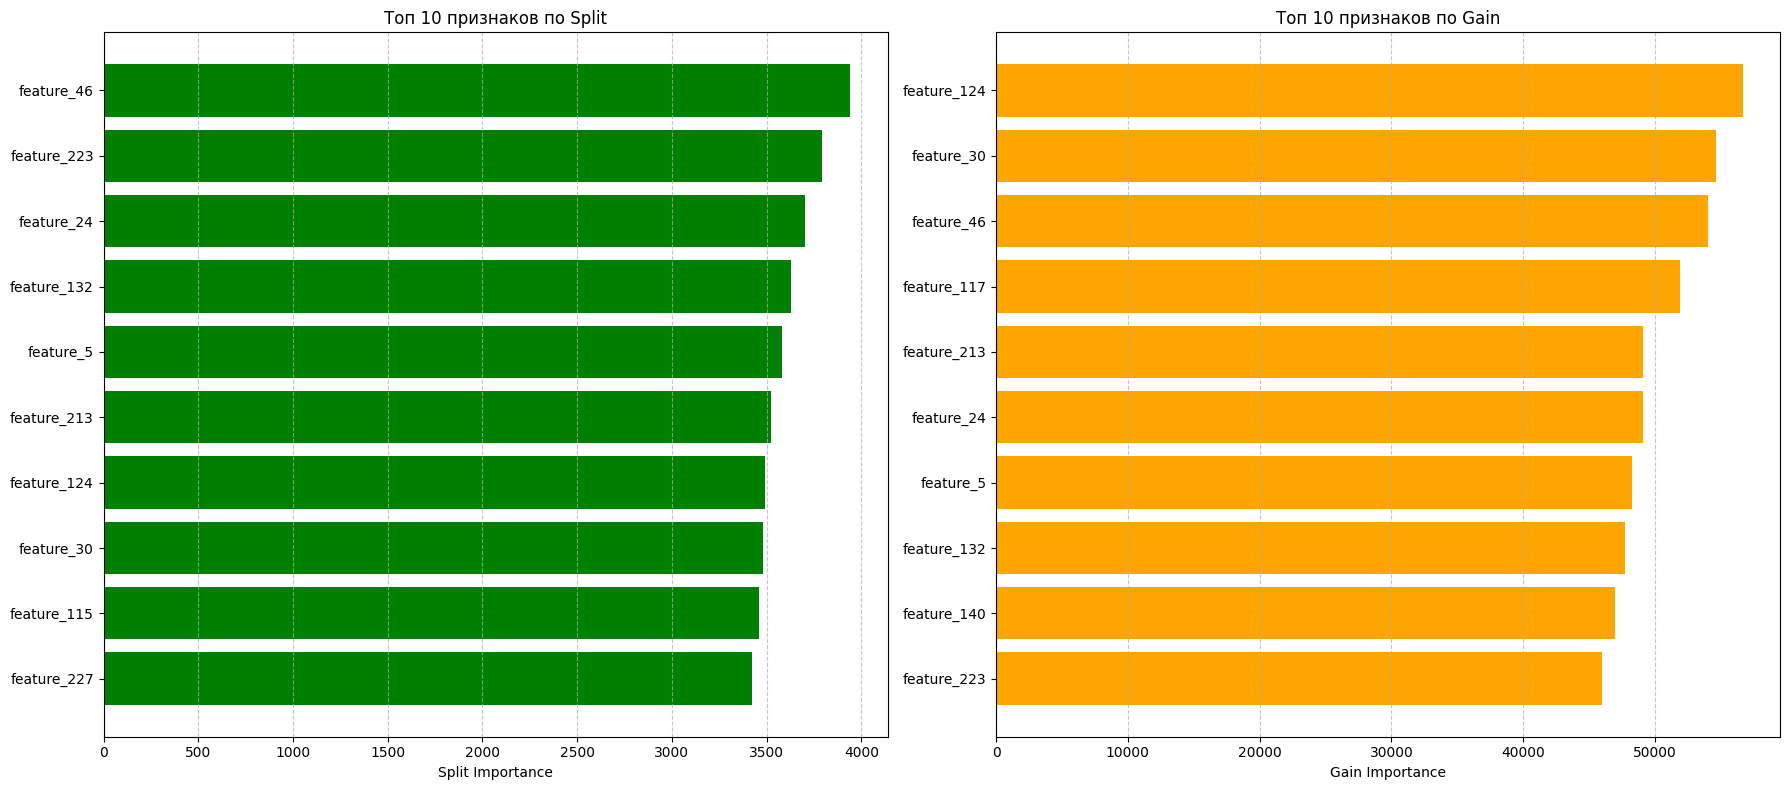

In [ ]:
importance_df = pd.DataFrame({
    'feature': features_optuna,
    'importance_split': model_lgb.feature_importance(importance_type='split'),
    'importance_gain': model_lgb.feature_importance(importance_type='gain')
})


fig, axes = plt.subplots(1, 2, figsize=(18, 8))

top_split = importance_df.sort_values('importance_split', ascending=False).head(10)
axes[0].barh(top_split['feature'][::-1], top_split['importance_split'][::-1], color='green')
axes[0].set_title(f'Топ 10 признаков по Split')
axes[0].set_xlabel('Split Importance')
axes[0].grid(axis='x', linestyle='--', alpha=0.7)

top_gain = importance_df.sort_values('importance_gain', ascending=False).head(10)
axes[1].barh(top_gain['feature'][::-1], top_gain['importance_gain'][::-1], color='orange')
axes[1].set_title(f'Топ 10 признаков по Gain')
axes[1].set_xlabel('Gain Importance')
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

**Вопрос:** Какие выводы можно сделать из полученных графиков?

Можно сделать вывод о самых важных признаках в нашей модели. Обе метрики являются показателям важности, более объективной можно считать gain, так как считается реальный вклад фичи в скор модели. Также видно что они взаимосвязаны, что в основном там одни и те же фичи находятся.

# Логрег

## plot_metric_time (1 балл)

**Задание:** Реализуйте функцию plot_metric_time, которая будет принимать на вход четыре аргумента, а именно:
- массив значений фичи,
- массив значений таргета,
- массив времени (аггрегированного по месяцам или кварталам, то есть `month` или `quarter` в вашей задаче, по дням рисовать не надо),
- метрику, которую необходимо отрисовать (нужно реализовать функцию для двух метрик: `IV` и `roc_auc`)
- число бакетов для вычисления `IV`, если выбрана эта метрика

Можете добваить какие-то ещё аргументы, если вам нужно

Если в фиче есть пропуски, функция должна убирать строки с пропусками из рассмотрения

**Hint**: можно, конечно, реализовать эту функцию через цикл, а можно попробовать разобраться и реализовать её через пандасовские `groupby` -> `apply`, это изящнее и быстрее

In [ ]:
import plotly.graph_objects as go

In [ ]:
def calc_iv(time_group: pd.DataFrame, n_buckets: int):
    vals = time_group['value'].values
    target = time_group['target'].values

    buckets = calc_buckets(vals, n_buckets=n_buckets)

    return calc_plot_title(vals, target, buckets)


def calc_auc(time_group: pd.DataFrame) -> float:
    vals = time_group['value'].values
    target = time_group['target'].values

    if len(np.unique(target)) < 2:
        return np.nan

    return roc_auc_score(target, vals)


def plot_metric_time(
        values: pd.Series,
        target: pd.Series,
        time: pd.Series,
        metric: str = 'IV',
        n_buckets_for_IV: int = 15
) -> go.Figure:

    feat_name = values.name

    data = pd.DataFrame({
        'value': values,
        'target': target,
        'time': time.astype(str)
    }).dropna().reset_index(drop=True)

    if metric == 'IV':
        time_metric = data.groupby('time').apply(
            lambda x: calc_iv(x, n_buckets_for_IV)
        )
    elif metric == 'roc_auc':
        time_metric = data.groupby('time').apply(
            calc_auc
        )
    else:
        raise NotImplementedError("only 'IV' and 'roc_auc' metrics are implemented")

    time_ticks = list(time_metric.index)
    metric_values = list(time_metric.values)

    plot_title = f"Динамика {metric} во времени ({feat_name})"
    fig = go.Figure()
    fig.add_trace(
        go.Scatter(
            x= time_ticks,
            y= metric_values,
            mode='markers+lines',
            name= str(feat_name)
            ))
    fig.update_layout(
            title_text=plot_title,
            yaxis=dict(title=metric),
            width=1000,
            height=450,
            xaxis=dict(
                domain=[0, .95],
                showgrid=True,
                tickvals=time_ticks,
                ),
            margin=dict(l=30, r=30, b=30, t=50),
            )
    fig.show()

    #return fig

In [ ]:
# примерно так это должно будет выглядеть
plot_metric_time(df['feature_124'], df['target'], df['quarter']) #

/tmp/ipykernel_1695/1107622355.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  time_metric = data.groupby('time').apply(


**Задание:** Возьмите **топ-15** фичей получившегося бустинга по важности по `gain`. Отрисуйте для них графики стабильности по `IV` во времени и удалите из рассмотрения те признаки, качество которых деградирует

**NB!** Обращайте внимание на масштаб оси *y!* Иногда признак стабильнее, чем кажется)

Если вам это мешает, можете поменять ось *y*, чтобы она начиналась от нуля в прошлом задании.

In [ ]:
importance_gain = model_lgb.feature_importance(importance_type='gain')

gain_df = pd.DataFrame({
    'feature': features_optuna,
    'gain': importance_gain
}).sort_values('gain', ascending=False).reset_index(drop=True)

top15_gain_features = gain_df['feature'].head(15).tolist()

print("Топ-15 признаков по Gain:")
for feat in top15_gain_features:
    print(f"{feat}   gain = {gain_df.loc[gain_df['feature'] == feat, 'gain'].values[0]:.0f}")

Топ-15 признаков по Gain:
feature_124   gain = 56656
feature_30   gain = 54641
feature_46   gain = 54058
feature_117   gain = 51913
feature_213   gain = 49081
feature_24   gain = 49078
feature_5   gain = 48282
feature_132   gain = 47755
feature_140   gain = 46983
feature_223   gain = 46006
feature_154   gain = 44568
feature_227   gain = 43773
feature_56   gain = 43701
feature_75   gain = 42890
feature_98   gain = 42365


На этом моменте предлагаю сделать новый маленький датафрейм, чтобы не "портить" исходный

И проводить все манипуляции с фичами на нём

In [ ]:
top15features_stable = top15_gain_features
df_for_logreg = df[top15features_stable + ['date', 'month', 'quarter', 'target', 'sample_part']].copy()

## Предобработка признаков (3 балла)

**Задание:** Используя функицю woe_line из ДЗ по логрегу, проверьте **числовые** фичи из полученного списка фичей на линейность по WoE на трейн-выборке (если в фиче есть пропуски - дропаем их при отрисовке)

Если фичи нелинейные, **линеаризуйте их**.

Преобразования, которые можно/стоит пробовать:
- клипы (`np.clip`) - зачастую их достаточно
- корень
- квадрат
- логарифм

Если нужно, можно прибавлять к фиче константу или менять её знак

При желании можно "распилить фичу на две половины" (если она немонотонна) и линеаризовать их по отдельности

Однако слишком упираться в линеаризацию фичей не нужно. Если фича ну совсем никак не линеаризуется, в крайнем случае можно её дропнуть или оставить как есть.

При отрисовке можно ограничиться 15-20 бактеами

In [ ]:
import plotly.graph_objects as go
from sklearn.metrics import roc_auc_score, r2_score
from sklearn.linear_model import LogisticRegression
from statsmodels.stats.proportion import proportion_confint
from scipy.special import logit

def woe_transform(badrate : float, offset : float) -> float:
    """Считаем WoE для бакета с данным badrate и выборки
    с данным offset."""
    woe = logit(badrate) - offset
    return woe

def woe_ci(target : np.ndarray, buckets : np.ndarray, offset : float, alpha: float = 0.05, method: str = 'wilson') -> Tuple[pd.Series]:
    """Для каждого бакета вычисляем WoE и доверительный
    интервал для него."""
    df = pd.DataFrame({'bucket': buckets, 'target': target})

    df_buckets = df.groupby('bucket')['target'].agg(
        bads='sum',
        nobs='count',
        badrate='mean'
    ).sort_index()

    badrate_lower_arr, badrate_upper_arr = proportion_confint(
        count=df_buckets['bads'],
        nobs=df_buckets['nobs'],
        alpha=alpha,
        method=method
    )

    # считаем бэдрейт и доверительный интервал для него (любым способом)
    badrate = df_buckets['badrate']
    badrate_lower = pd.Series(badrate_lower_arr, index=df_buckets.index)
    badrate_upper = pd.Series(badrate_upper_arr, index=df_buckets.index)

    # переходим от бэдрейта к woe
    woe = woe_transform(badrate, offset)
    woe_lower = woe_transform(badrate_lower, offset)
    woe_upper = woe_transform(badrate_upper, offset)

    return woe, woe_lower, woe_upper


def calc_line(values : np.ndarray, target : np.ndarray, mean_feature : np.ndarray, offset : float) -> np.ndarray:
    """Строим линейную интерполяцию для WoE."""

    # строим логистическую регрессию на одном признаке
    # и считаем ее предсказания в точках – mean_feature
    model = LogisticRegression(penalty=None, solver='lbfgs')
    model.fit(values.reshape(-1, 1), target)

    proba = model.predict_proba(mean_feature.reshape(-1, 1))[:, 1]
    line = woe_transform(proba, offset)
    return line

def calc_buckets_info(values : np.ndarray, target : np.ndarray, buckets : np.ndarray) -> dict:
    """Для каждого бакета расчитывает
     - среднее значение признака
     - линейную интерполяцию в пространстве woe
     - значение woe и доверительный интервал для него"""
    offset = logit(np.mean(target))
    mean_feature = pd.Series(values).groupby(buckets).mean().sort_index().values
    woe, woe_lower, woe_upper = woe_ci(target, buckets, offset)
    line = calc_line(values, target, mean_feature, offset)

    buckets_info = {
        "mean_feature" : mean_feature,
        "line"         : line,
        "woe"          : woe.values,
        "woe_lower"    : woe.values - woe_lower.values,
        "woe_upper"    : woe_upper.values - woe.values
    }

    return buckets_info

def calc_plot_title(
        values : np.ndarray,
        target : np.ndarray,
        buckets : np.ndarray
    ) -> str:
    """Считает для признака roc auc, IV, R^2"""
    auc = roc_auc_score(target, values)

    # формула выше
    df = pd.DataFrame({'value': values, 'target': target, 'bucket': buckets})

    df_buckets = df.groupby('bucket').agg(
        mean_feature=('value', 'mean'),
        bads=('target', 'sum'),
        goods=('target', lambda x: (x == 0).sum()),
        total=('target', 'count'),
        badrate=('target', 'mean')
    ).sort_index()

    B_total = df_buckets['bads'].sum()
    G_total = df_buckets['goods'].sum()
    offset = logit(np.mean(target))

    woe = woe_transform(df_buckets['badrate'], offset)

    bad_dist = df_buckets['bads'] / B_total
    good_dist = df_buckets['goods'] / G_total

    IV = np.sum((bad_dist - good_dist) * woe)

    # Взвешенный R^2
    # X - среднее в бакете, Y - woe в бакете, вес – число наблюдений в бакете
    line = calc_line(values, target, df_buckets['mean_feature'].values, offset)
    R_sqr = r2_score(y_true=woe, y_pred=line, sample_weight=df_buckets['total'])

    plot_title = (
        f"AUC = {auc:.3f} "
        f"IV = {IV:.3f} "
        f"R_sqr = {R_sqr:.3f} "
    )

    return plot_title


def make_figure(buckets_info : dict, plot_title : str) -> go.Figure:
    """Строит график линейности."""
    fig = go.Figure()

    # общие настройки
    title = dict(
        text=plot_title,
        y=0.95,
        x=0.5,
        font=dict(size=12),
        xanchor="center",
        yanchor="top"
    )
    margin = go.layout.Margin(
        l=50,
        r=50,
        b=50,
        t=60
    )

    fig.add_trace(
        go.Scatter(
            x=buckets_info["mean_feature"],
            y=buckets_info["line"],
            mode='lines',
            name="interpolation_line",
            showlegend=False
        )
    )

    fig.add_trace(
        go.Scatter(
            x=buckets_info["mean_feature"],
            y=buckets_info["woe"],
            line=dict(
                color='firebrick',
                width=1,
                dash='dot'
            ),
            error_y=dict(
                type='data',
                symmetric=False,
                array=buckets_info["woe_upper"],
                arrayminus=buckets_info["woe_lower"]
            ),
            name="WoE",
            showlegend=False)
    )

    fig.update_layout(
        width=1000,
        height=450,
        xaxis_title=dict(
            text='Feature value',
            font=dict(size=12)
        ),
        yaxis_title=dict(
            text="WoE",
            font=dict(size=12)
        ),
        title=title,
        margin=margin
    )

    return fig


def woe_line(
        values : np.ndarray,
        target : np.ndarray,
        n_buckets : int
    ) -> go.Figure:
    """График линейности переменной по WoE."""
    buckets : np.ndarray = calc_buckets(values, n_buckets)
    buckets_info : pd.DataFrame = calc_buckets_info(values, target, buckets)
    plot_title : str = calc_plot_title(values, target, buckets)
    fig = make_figure(buckets_info, plot_title)
    return fig

In [ ]:
X_train = df_for_logreg[df_for_logreg['sample_part'] == 'train'].copy().dropna()
num_features = X_train[top15features_stable].select_dtypes(include='number').columns.tolist()


In [ ]:
def compare_transformation(df_sub, feature_name, y, transform_func):
    """Отрисовывает графики линейности до и после применения трансформации."""
    val_orig = df_sub[feature_name].values

    print(f"{feature_name} до преобразования")
    fig_before = woe_line(val_orig, y, n_buckets=15)
    fig_before.show()

    val_trans = transform_func(val_orig)
    print(f"{feature_name} после преобразования ")
    fig_after = woe_line(val_trans, y, n_buckets=15)
    fig_after.show()

In [ ]:
feat_name = num_features[2]
y_train = X_train[TARGET].values
vals = X_train[feat_name].values
low = np.percentile(vals, 5)
high = np.percentile(vals, 95)
# lambda x: np.clip(x, low, high)

trans_fun = lambda x: np.clip(x, low, high)

compare_transformation(X_train, feat_name, y_train, trans_fun)

feature_46 до преобразования


feature_46 после преобразования 


In [ ]:
f213 = X_train['feature_213']
f213_low, f213_high = np.percentile(f213, 5), np.percentile(f213, 95)

dict_transform = {
    'feature_30': lambda x: np.log(x + 1e-5),
    'feature_213': lambda x: np.log1p(np.abs(x)),
    'feature_46': lambda x: -(x ** 2),
    'feature_132': lambda x: -(x ** 2),
    'feature_213': lambda x: np.clip(x, np.percentile(vals, 5), np.percentile(vals, 95)),
}

for feat, func in dict_transform.items():
    if feat in df_for_logreg.columns:
        df_for_logreg[feat] = func(df_for_logreg[feat])

Пришло время заполнить пропуски.

Самый простой вариант для числовых признаков - заполнить их средним значением фичи

**Вопрос**: какие проблемы могут возникнуть при таком заполнении пропусков?

**Задание**: Проверьте, что заполнение средним значением адекватно для тех признаков, где есть пропуски (hint: в нашем датасете - почти всегда адекватно). Если нет, придумайте, как ещё можно заполнить пропуски. Ну и заполните их)

- Из проблем это уменьшение дисперсии, потеря потенциалньо полезных данных, возможно пропуск там возник не случайно. Ну и будет слишком много точек со средним которые уменьшат чувствительность к остальным примерам.

- Проверка будет простая на среднее таргета в пропущенных значениях фичи, если оно сильно отличается значит пропуск там возник не случайно и имеет какой-то смысл.

In [ ]:
df_train = df_for_logreg[df_for_logreg['sample_part'] == 'train'].copy()

na_cols = [c for c in top15features_stable if df_train[c].isna().sum() > 0]

overall_mean_target = df_train[TARGET].mean()
print(f"Общий средний таргет на train: {overall_mean_target:.4f}\n")

for col in na_cols:
    na_target = df_train.loc[df_train[col].isna(), TARGET].mean()
    print(f"{col}: таргет у NaN = {na_target:.4f} vs общий = {overall_mean_target:.4f}")

print()
print(df_train[top15features_stable].isna().sum())

for col in na_cols:
    mean_val = df_train[col].mean()
    df_for_logreg[col] = df_for_logreg[col].fillna(mean_val)

print()
print(df_for_logreg[top15features_stable].isna().sum())

Общий средний таргет на train: 0.7093

feature_124: таргет у NaN = 0.7078 vs общий = 0.7093
feature_30: таргет у NaN = 0.7070 vs общий = 0.7093
feature_140: таргет у NaN = 0.7062 vs общий = 0.7093
feature_223: таргет у NaN = 0.7081 vs общий = 0.7093

feature_124    29480
feature_30     17260
feature_46         0
feature_117        0
feature_213        0
feature_24         0
feature_5          0
feature_132        0
feature_140    18479
feature_223    36734
feature_154        0
feature_227        0
feature_56         0
feature_75         0
feature_98         0
dtype: int64

feature_124    0
feature_30     0
feature_46     0
feature_117    0
feature_213    0
feature_24     0
feature_5      0
feature_132    0
feature_140    0
feature_223    0
feature_154    0
feature_227    0
feature_56     0
feature_75     0
feature_98     0
dtype: int64


Вспомним про категориальные признаки, их нужно закодировать.

**Задание:** Используя `OneHotEncoder` закодируйте категориальные признаки.

In [ ]:
from sklearn.preprocessing import OneHotEncoder
#cat_features

df_cat_all = df[cat_features].astype(str)
df_cat_train = df_cat_all[df['sample_part'] == 'train']

ohe = OneHotEncoder(
    sparse_output=False,
    drop='first',
    handle_unknown='ignore'
)

ohe.fit(df_cat_train)
ohe_array = ohe.transform(df_cat_all)
ohe_col_names = ohe.get_feature_names_out(cat_features)
df_ohe = pd.DataFrame(
    ohe_array,
    columns=ohe_col_names,
    index=df.index
)

df_for_logreg = pd.concat([df_for_logreg, df_ohe], axis=1)
df_for_logreg

,feature_124,feature_30,feature_46,feature_117,feature_213,feature_24,feature_5,feature_132,feature_140,feature_223,...,feature_157_8,feature_157_9,feature_161_1.0,feature_161_nan,feature_165_1,feature_168_1,feature_179_1,feature_209_PRIV,feature_209_UNEMP,feature_222_1
22620,-61.495238,-3.303845,115.319640,-17.226707,7.458468,-7.179830,-215.945717,-51.036000,15.000000,38.981027,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0
478621,-28.477404,-2.820649,172.981221,-8.564242,10.884534,-23.797875,-170.713568,-12.897176,28.000000,190.190523,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
372254,-42.005982,-2.481733,119.580242,-10.249472,17.206131,-22.976857,-154.503339,-42.238052,10.000000,126.159664,...,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0
2596,-42.117574,-3.862373,85.009499,-13.114987,18.618423,-14.087877,-131.553444,-21.097818,22.000000,100.129520,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0
216892,-48.599477,-2.404064,43.108790,-7.378194,8.274292,-17.195954,-162.092621,-21.926765,50.000000,53.473490,...,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
196513,-34.698016,-3.694805,266.894924,-13.148536,8.779791,-1.997241,-160.271802,-1.478616,23.000000,89.118563,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0
108604,-57.378146,-4.580360,30.165443,-18.802413,15.597165,-11.417951,-90.369206,-11.276870,50.000000,180.214906,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
141359,-46.912357,-4.315126,260.779150,-11.941628,12.702745,-32.527420,-155.056899,145.049609,46.000000,76.055231,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0
443018,-28.192184,-3.144931,3.294182,-12.865323,10.443730,-3.723810,-139.585458,-220.017691,26.000000,47.621882,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


## Stepwise и обучение логрега (5 баллов)

**Задание (boss)**: Реализуйте Stepwise-алгоритм.

Ваша функция `stepwise` должна принимать на вход:
- Датафрейм со всеми признаками и таргетом
- список с именами рассматриваемых признаков
- строку-имя таргета
- уровни значимости `alpha_in` и `alpha_out`

И возвращать список отобранных признаков.

Во время работы пусть она также выводит, какой признак был включён или исключён и с каким `p-value`

In [ ]:
from scipy.stats.distributions import chi2
from sklearn.metrics import log_loss

In [ ]:
def likelihood_ratio_test(ll_short, ll_long):

    """
    вспомогательная функция
    рассчитывает значение p-value для теста отношения правдоподобия
    ll_short — логарифм правдоподобия модели на k переменных
    ll_long — логарифм правдоподобия модели на k+1 переменной

    Returns
    -----
    p-value
    """
    lr = -2 * (ll_short - ll_long)
    return chi2.sf(lr, 1)

In [ ]:
def calc_ll(X: np.ndarray, y: np.ndarray) -> float:
    model = LogisticRegression(penalty=None, solver='lbfgs', max_iter=200, random_state=42, n_jobs=-1)
    model.fit(X, y)
    y_pred_proba = model.predict_proba(X)[:, 1]

    return -log_loss(y, y_pred_proba, normalize=False)

def stepwise(
        df: pd.DataFrame,
        features: list[str],
        target: str,
        alpha_in: float = 0.01,
        alpha_out:  float = 0.05
        ) -> list[str]:


    selected_features = list()
    y = df[target].values

    while True:

        # forward:
        best_feature = None
        min_p_val = 1.0

        if (len(selected_features) < len(features)):
            remaining_features = [f for f in features if f not in selected_features]

            # Если еще ничего не выбрано — базовой точкой служит константная модель (средний таргет)
            if len(selected_features) == 0:
                p_const = np.full(shape=len(y), fill_value=np.mean(y))
                ll_short = -log_loss(y, p_const, normalize=False)
            else:
                ll_short = calc_ll(df[selected_features].values, y)

            for cand in remaining_features:
                X_cand = df[selected_features + [cand]].values
                ll_long = calc_ll(X_cand, y)

                cur_pval = likelihood_ratio_test(ll_short, ll_long)

                if cur_pval < min_p_val:
                    min_p_val = cur_pval
                    best_feature = cand


            if best_feature and min_p_val < alpha_in:
                selected_features.append(best_feature)
                print(f"В модель была добавлена переменная {best_feature}, p-value: {round(min_p_val, 6)}")
            else:
                best_feature = None

        # backward
        worst_feature = None
        if (len(selected_features) > 1):

            ll_long = calc_ll(df[selected_features].values, y)
            max_p_val = -1.0

            for feat in selected_features:
                feats_without = [f for f in selected_features if f != feat]
                ll_short = calc_ll(df[feats_without].values, y)

                cur_pval = likelihood_ratio_test(ll_short, ll_long)

                if cur_pval > max_p_val:
                    max_p_val = cur_pval
                    worst_candidate = feat

            if max_p_val >= alpha_out:
                worst_feature = worst_candidate
                selected_features.remove(worst_feature)
                print(f"Из модели была удалена переменная {worst_feature}, p-value: {round(max_p_val, 6)}")

        if not (best_feature or worst_feature):
            break # но вы можете сформулировать критерий останова по-другому, если вам так будет удобнее писать

    return selected_features

Запустите ваш алгоритм на отобранных фичах со значениями `alpha_in = 0.01`, `alpha_out = 0.02`

Если в степвайз заходят *все переменные*, причём с очень маленькими `p-value` - это неудивительно, ведь вы уже провели серьёзный предварительный отбор фичей.

Чтобы убедиться в коректности работы своего алгоритма, можете попробовать запустить его на каких-нибудь других фичах, откинутых сильно ранее

In [ ]:
X_train = df_for_logreg[df_for_logreg['sample_part'] == 'train'][top15features_stable + [TARGET]]
candidate_features = [
    col for col in df_for_logreg.columns
    if col not in ['date', 'month', 'quarter', TARGET, 'sample_part']
]

print(f"{len(candidate_features)}")

selected_features = stepwise(
    df=X_train,
    features=top15features_stable,
    target=TARGET,
    alpha_in = 0.01,
    alpha_out = 0.02
    )

print(f"{len(selected_features)}")

57
В модель была добавлена переменная feature_124, p-value: 0.0
В модель была добавлена переменная feature_30, p-value: 0.0
В модель была добавлена переменная feature_117, p-value: 0.0
В модель была добавлена переменная feature_140, p-value: 0.0
В модель была добавлена переменная feature_154, p-value: 0.0
В модель была добавлена переменная feature_24, p-value: 0.0
В модель была добавлена переменная feature_46, p-value: 0.0
В модель была добавлена переменная feature_223, p-value: 0.0
В модель была добавлена переменная feature_213, p-value: 0.0
В модель была добавлена переменная feature_75, p-value: 0.0
В модель была добавлена переменная feature_5, p-value: 0.0
11


**Задание**: На получившемся наборе признаков обучим, наконец, логрег!

Для обучения можно использовать трейн + валидацию вместе, либо просто трейн

*Не забудьте отскалировать фичи*

In [ ]:
from sklearn.preprocessing import StandardScaler # Или другой скейлер
from sklearn.linear_model import LogisticRegression
from scipy.special import logit

In [ ]:
print(ohe_col_names)

['feature_0_b' 'feature_0_c' 'feature_0_d' 'feature_10_1.0'
 'feature_10_nan' 'feature_31_1' 'feature_31_2' 'feature_37_1'
 'feature_37_10' 'feature_37_11' 'feature_37_2' 'feature_37_3'
 'feature_37_4' 'feature_37_5' 'feature_37_6' 'feature_37_7'
 'feature_37_8' 'feature_37_9' 'feature_62_1.0' 'feature_62_nan'
 'feature_144_1' 'feature_147_1' 'feature_157_1' 'feature_157_10'
 'feature_157_11' 'feature_157_12' 'feature_157_2' 'feature_157_3'
 'feature_157_4' 'feature_157_5' 'feature_157_6' 'feature_157_7'
 'feature_157_8' 'feature_157_9' 'feature_161_1.0' 'feature_161_nan'
 'feature_165_1' 'feature_168_1' 'feature_179_1' 'feature_209_PRIV'
 'feature_209_UNEMP' 'feature_222_1']


In [ ]:
final_features = selected_features + ohe_col_names.tolist()

train_val_mask = df_for_logreg['sample_part'].isin(['train', 'val'])

scaler = StandardScaler()
scaler.fit(df_for_logreg.loc[train_val_mask, selected_features])
df_for_logreg.loc[:, selected_features] = scaler.transform(df_for_logreg[selected_features])

X_train_val = X_train_val = df_for_logreg.loc[train_val_mask, final_features].values
y_train_val = df_for_logreg.loc[train_val_mask, TARGET].values
X_all = df_for_logreg[final_features].values

logreg = LogisticRegression(penalty=None, solver='lbfgs', max_iter=1000)
logreg.fit(X_train_val, y_train_val)


df_for_logreg['logreg'] = logreg.predict_proba(X_all)[:, 1]
df_for_logreg['logit_logreg'] = logit(df_for_logreg['logreg'])

**Задание:** Оцените качество получившегося логрега **на тестовой выборке** по метрике `roc_auc`.

**Ваша задача - побить** `threshold_auc = 0.622`. Если этого сделать ну совсем не получается, попробуйте добавить в модель ещё переменных (но должно получаться :)

**Также:**

- Постройте графики линейности по WoE получившегося логрега на трейне и тестовой выборке (оценивайте линейность для `logit_logreg`, а не для вероятности!)
- Постройте график стабильности `roc_auc` во времени для получившегося логрега

In [ ]:
from sklearn.metrics import roc_auc_score

y_test = df_for_logreg.loc[df_for_logreg['sample_part'] == 'test', TARGET]
y_test_pred = df_for_logreg.loc[df_for_logreg['sample_part'] == 'test', 'logreg']

test_auc = roc_auc_score(y_test, y_test_pred)
print(f"ROC-AUC на тесте: {test_auc:.3f}")

ROC-AUC на тесте: 0.623


In [ ]:
train_mask = df_for_logreg['sample_part'] == 'train'
test_mask = df_for_logreg['sample_part'] == 'test'


fig = woe_line(
    df_for_logreg.loc[train_mask, 'logit_logreg'].values,
    df_for_logreg.loc[train_mask, TARGET].values,
    n_buckets=15)
fig

In [ ]:
fig = woe_line(
    df_for_logreg.loc[test_mask, 'logit_logreg'].values,
    df_for_logreg.loc[test_mask, TARGET].values,
    n_buckets=15)
fig

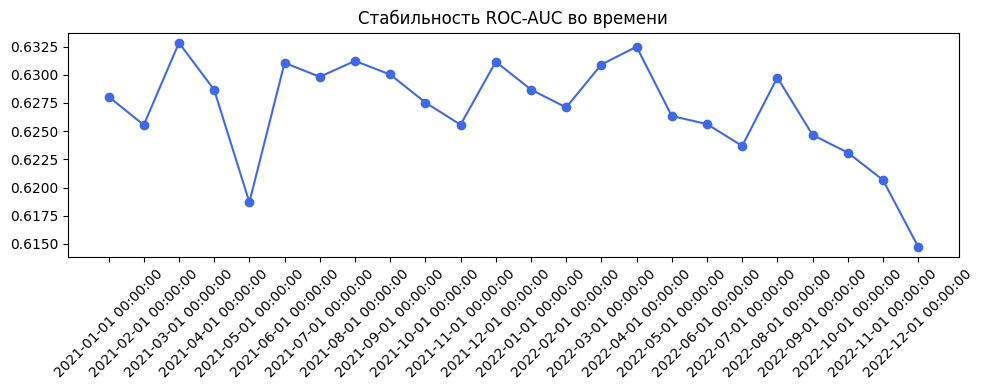

In [ ]:
time_col = 'month'

auc_by_period = []
for period, group in df_for_logreg.groupby(time_col):
    if group[TARGET].nunique() == 2:
        auc_val = roc_auc_score(group[TARGET], group['logreg'])
        auc_by_period.append({
            'period': str(period),
            'auc': auc_val
        })

df_auc_time = pd.DataFrame(auc_by_period)

plt.figure(figsize=(10, 4))
plt.plot(df_auc_time['period'], df_auc_time['auc'], marker='o', color='royalblue', label='ROC-AUC по периодам')
plt.title(f'Стабильность ROC-AUC во времени')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Задание:** Визуализируйте важность фичей полученной линейной модели.

In [ ]:
import shap


X_test_df = df_for_logreg.loc[test_mask, final_features].copy()
explainer = shap.LinearExplainer(
    logreg,
    X_test_df
)

shap_values = explainer(X_test_df)

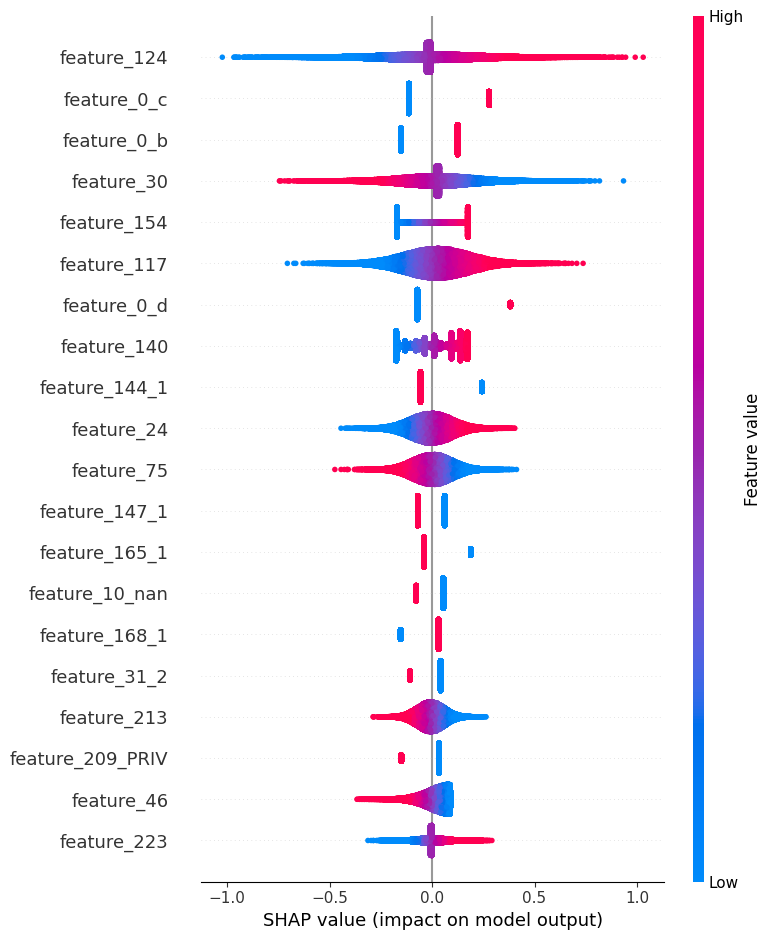

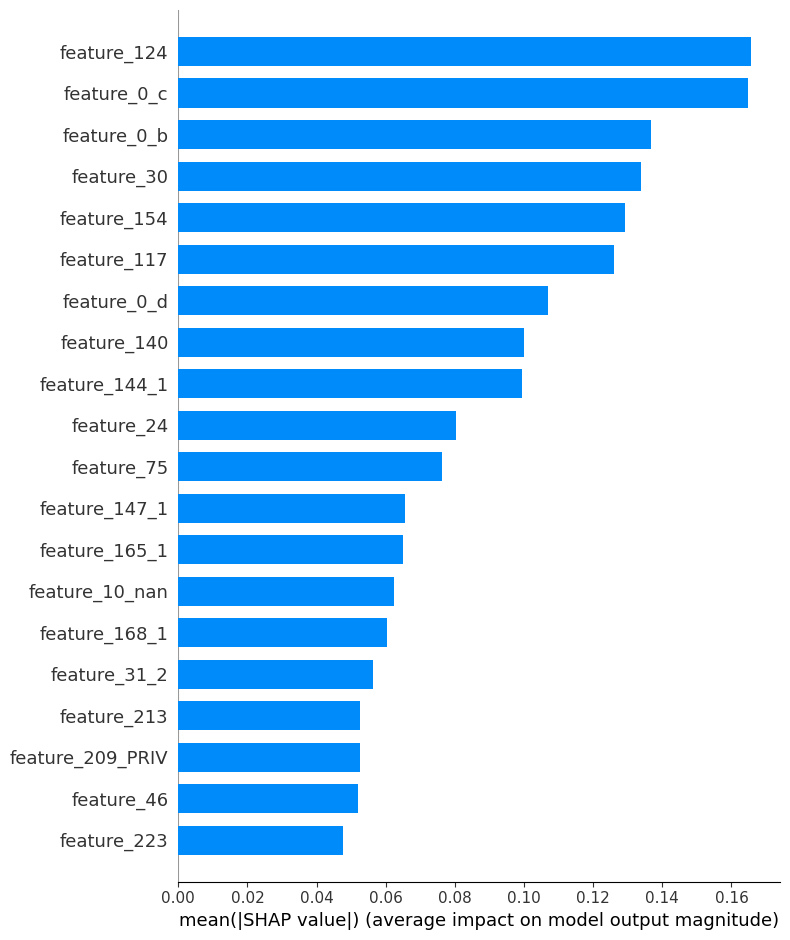

In [ ]:
# TODO: постройте beeswarm plot
shap.summary_plot(shap_values, X_test_df, feature_names=final_features)

# TODO: постройте bar plot (агрегированная важность)
shap.summary_plot(shap_values, X_test_df, feature_names=final_features, plot_type='bar')


# Бонусная часть (4 балла)

В разделе про бустинг мы обучали `LGBMClassifier` на довольно большом наборе фичей. Их количество можно сократить, при этом не теряя в качестве модели.

За начальный набор признаков можно взять все признаки (все 230) или признаки после отбора по IV.

**Ваша задача:** Отобрать признаки, подобрать оптимальные гиперпараметры и обучить `LGBMClassifier`.

Задание творческое) Можно использовать любые методы отбора признаков / оптимизации гиперпараметров.

**Чем меньше признаков, без ухудшения качества модели – тем лучше.**

In [ ]:
train_data = df[df['sample_part'] == 'train']
valid_data = df[df['sample_part'] == 'val']
test_data = df[df['sample_part'] == 'test']

X_train = train_data[features_optuna]
y_train = train_data[TARGET].values

X_valid = valid_data[features_optuna]
y_valid = valid_data[TARGET].values

X_test = test_data[features_optuna]
y_test = test_data[TARGET].values

train_data = lgb.Dataset(X_train, label=y_train)
valid_data = lgb.Dataset(X_valid, label=y_valid, reference=train_data)
test_data = lgb.Dataset(X_test, label=y_test)

best_params = study.best_params.copy()
best_params.update({'objective': 'binary', 'metric': 'auc', 'verbosity': -1, 'random_state': RANDOM_STATE})

callbacks = [lgb.early_stopping(stopping_rounds=30, verbose=False), lgb.log_evaluation(period=0)]

model_lgb = lgb.train(
    best_params,
    train_data,
    num_boost_round=1000,
    valid_sets=[valid_data],
    callbacks=callbacks,
)

y_test_pred = model_lgb.predict(X_test, num_iteration=model_lgb.best_iteration)
test_auc = roc_auc_score(y_test, y_test_pred)

print(f"Лучшая итерация (best_iteration): {model_lgb.best_iteration}")
print(f"Финальный ROC-AUC на тесте: {test_auc:.4f}")

Лучшая итерация (best_iteration): 1000
Финальный ROC-AUC на тесте: 0.7381


In [ ]:
current_features = list(features_optuna)
best_val_auc, cur_model = evaluate_features(current_features)
print(f"Старт: признаков = {len(current_features)}, Val ROC-AUC = {best_val_auc:.5f}\n")

67

In [ ]:
gain_imp = model_lgb.feature_importance(importance_type='gain')

df_imp = pd.DataFrame({
    'feature': features_optuna,
    'gain': gain_imp
}).sort_values('gain', ascending=False).reset_index(drop=True)

top40_features = df_imp['feature'].iloc[:40].tolist()

train_data_40 = lgb.Dataset(X_train[top40_features], label=y_train)
valid_data_40 = lgb.Dataset(X_valid[top40_features], label=y_valid, reference=top40_features)

model_lgb_40 = lgb.train(
    params=best_params,
    train_set=train_data_40,
    num_boost_round=1000,
    valid_sets=[valid_data_40],
    callbacks=callbacks
)

y_test_pred_40 = model_lgb_40.predict(X_test[top40_features], num_iteration=model_lgb_40.best_iteration)
test_auc_40 = roc_auc_score(y_test, top40_features)

print(f"Признаков: {len(top40_features)}")
print(f"Test ROC-AUC на топ-30 фичах: {test_auc_40:.4f}")

Признаков: 40
Test ROC-AUC на топ-30 фичах: 0.7244


Так как в заданни не сказано, что именно значит не терять в качестве, тем более, что мы делали отбор по IV. То я просто взял топ 30 фичей по gain. Качество сильно не ухудшилось. Можно было конечно убирать постепенно по признаку и смотреть качеству, но это довольно долго будет. Но есть пару других идей, которые можно реализовать.

Не знаю есть ли такой метод, но могу предположить, что должен быть. Мы берем например вместо признака случайный шум и считаем метрику, если она сильно просела, значит признак важный.

P.S. Прочитал про permutation importance, разница с моим рассждением в перемешивании значений столбца для сохранения порядка и распределения. На тех же рассужениях и BorutaShap

Протестить я не смог, а дедлайн горит)

Идеи для отбора признаков:

- Воспользоваться методами из модуля `sklearn.feature_selection` (точно можно попробовать RFE). Документация https://scikit-learn.org/stable/modules/feature_selection.html
<!-- - С помощью `BorutaPy` из библиотеки `boruta` (https://towardsdatascience.com/simple-example-using-boruta-feature-selection-in-python-8b96925d5d7a – статья может помочь разобраться с запуском алгоритма (мб не откроется без vpn)) -->
- permutation importance и elimination по нему (https://scikit-learn.org/stable/modules/permutation_importance.html)
- попробовать использовать shap-values

In [ ]:
# your answere here